# Tema 29 · Modelos generativos: autoencoders, GANs y difusión

Modelos que no solo reconocen, sino que crean imágenes nuevas.

Este cuaderno es el tema 29 de la [ruta de aprendizaje de la OBIA](https://iabolivia.org/aprende/aprendizaje-automatico/): la teoría y los ejercicios de [la página del tema](https://iabolivia.org/aprende/aprendizaje-automatico/29-modelos-generativos-autoencoders-gans-y-difusion/), con todo su código. Ejecuta las celdas en orden, de arriba abajo (o *Entorno de ejecución → Ejecutar todas*).

Debajo de cada celda está la salida que dio cuando se escribió el tema. Al ejecutarla, la tuya puede variar en los últimos decimales. Las actividades interactivas están en la página del tema.

Este tema entrena o usa redes grandes: en Colab, *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU* lo hace mucho más rápido.

Primero, las bibliotecas que este tema necesita y que Colab no trae (o trae en otra versión):

In [ ]:
!pip install -q diffusers==0.42.1

# Teoría

## La pregunta

Todos los modelos de la ruta hasta ahora **reconocen**: reciben una foto y dicen «es un botín», reciben una reseña y dicen «es positiva». ¿Se puede ir al revés? ¿Puede una red **crear** una foto de un botín que no existe, o un dígito escrito por nadie?

Para crear, un modelo tiene que haber aprendido cómo son los datos: no solo qué los separa, sino qué forma tienen todos juntos. En este tema vas a construir tres maneras de lograrlo, cada una con una idea distinta:

- un **autoencoder**, que aprende a comprimir una imagen en pocos números y a reconstruirla;
- una **GAN**, donde dos redes juegan: una falsifica y la otra intenta descubrir las falsificaciones;
- un **modelo de difusión**, que aprende a quitar ruido poco a poco hasta que del ruido puro sale una imagen.

Al final vas a usar un modelo de difusión preentrenado, de la misma familia que los generadores de imágenes que conoces, y a hablar de sus riesgos.

Necesitas PyTorch y el bucle de entrenamiento del tema 18 («PyTorch: tensores, autograd y el bucle de entrenamiento»), las redes convolucionales del tema 20 («Redes convolucionales») y FashionMNIST, que ya usaste en los dos. También ayudan la idea de comprimir con pocas coordenadas del tema 15 («Reducir dimensiones: PCA, t-SNE y UMAP») y la pareja codificador-decodificador del tema 25 («Reutilizar modelos: BERT, codificador-decodificador y ajuste fino»).

## Actividad: ruido y vuelta

El primer panel tiene 150 puntos que forman una espiral. El deslizador *t* los cubre de ruido al azar: a más *t*, más ruido. El botón «Reconstruir» hace el camino de vuelta con un **modelo de difusión** de verdad, entrenado con el mismo código que vas a escribir más abajo; los caminos están calculados de antemano y aquí solo se reproducen.

El segundo panel es una **GAN** que aprende una sola variable. Las barras son el histograma de lo que produce el generador; la línea gruesa, el de los datos reales. La curva de abajo es el discriminador: qué probabilidad le da a cada valor de ser real. También es un entrenamiento real, guardado en 16 momentos.

> **Actividad interactiva:** está en la [página del tema](https://iabolivia.org/aprende/aprendizaje-automatico/29-modelos-generativos-autoencoders-gans-y-difusion/teoria/). Ábrela en el navegador para usarla.
Prueba esto, en orden:

1. Sube *t* de 10 en 10 hasta 100. ¿En qué momento dejas de reconocer la espiral? ¿Qué forma tiene la nube con *t* = 100?
2. Con *t* = 100, pulsa «Reconstruir». ¿Vuelve a aparecer la espiral? Mira el punto coral: ¿regresa a su círculo vacío?
3. Repite con *t* = 10 y con *t* = 50. Compara la cifra «a su lugar» de cada caso. ¿Qué diferencia hay entre quitar un poco de ruido y quitarlo todo?
4. En el panel de la GAN, pulsa «Entrenar». ¿Hacia dónde se mueven las barras? ¿Qué le pasa a la curva del discriminador cuando el generador ya imita bien a los datos?
5. Busca el paso 2500. ¿Qué le pasó al generador? ¿Se recupera después?

Lo que viste es el centro del tema: **la difusión aprende a quitar ruido, y si arranca del ruido puro, inventa datos nuevos con la forma de los de entrenamiento**. La GAN llega a lo mismo por otro camino, un juego entre dos redes que no siempre es estable.

## Autoencoders: comprimir y reconstruir

Un **autoencoder** es una red que aprende a copiar su entrada. Parece inútil, pero tiene una trampa: en el medio hay un **cuello de botella**, una capa con muy pocas neuronas. Para copiar bien, la red tiene que aprender a resumir la imagen en esos pocos números.

- El **codificador** convierte la imagen (784 píxeles) en un vector corto *z*: su **código latente**.
- El **decodificador** convierte *z* otra vez en una imagen de 784 píxeles, la **reconstrucción** *x̂*.
- La pérdida compara la reconstrucción con la original píxel a píxel: el error cuadrático medio del tema 6.

$$z = \text{codificador} ( x ) \qquad \hat{x} = \text{decodificador} ( z )$$

$$L = \frac{1}{784} \sum_{i = 1}^{784} {( {x}_{i} - {\hat{x}}_{i} )}^{2}$$

No hacen falta etiquetas: el objetivo es la propia imagen. Es aprendizaje **sin supervisión**, como el clustering y el PCA de la fase 3. De hecho, un autoencoder con capas lineales y sin activaciones aprende lo mismo que el PCA del tema 15: proyectar sobre las direcciones que más varían. Con activaciones no lineales puede aprender formas más curvas.

### Los datos

Usamos 10 000 prendas de FashionMNIST (Xiao, Rasul y Vollgraf, Zalando Research, 2017; licencia MIT) para entrenar
 y 2000 de prueba para validar, como en el tema 20, para que todo corra rápido sin GPU. Esta vez no normalizamos: dejamos los píxeles entre 0 y 1, porque la red tiene que devolver una imagen en esa misma escala.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets
from torchvision.utils import make_grid

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
# Del blanco al color "C0": la prenda oscura sobre fondo claro
tinta = LinearSegmentedColormap.from_list("tinta", ["white", "C0"])

entrenamiento = datasets.FashionMNIST(root="datos", train=True,
                                      download=True)
prueba = datasets.FashionMNIST(root="datos", train=False, download=True)
nombres = ["polera", "pantalón", "chompa", "vestido", "abrigo",
           "sandalia", "camisa", "zapatilla", "bolso", "botín"]

g = torch.Generator().manual_seed(0)
idx_ent = torch.randperm(len(entrenamiento), generator=g)[:10000]
idx_val = torch.randperm(len(prueba), generator=g)[:2000]
# Píxeles entre 0 y 1; cada imagen aplanada en un vector de 784
x_ent = entrenamiento.data[idx_ent].float().div(255).view(-1, 784)
x_val = prueba.data[idx_val].float().div(255).view(-1, 784)
y_val = prueba.targets[idx_val]
print("Entrenamiento:", tuple(x_ent.shape), " validación:",
      tuple(x_val.shape))
print(f"Píxeles entre {x_ent.min():.0f} y {x_ent.max():.0f}")

Entrenamiento: (10000, 784)  validación: (2000, 784)
Píxeles entre 0 y 1


### El modelo y el bucle

El codificador va de 784 a 256 y de 256 a 16 números; el decodificador hace el camino inverso. La última capa usa una **sigmoide**, que deja cada píxel de la salida entre 0 y 1, como los de la entrada.

La función `entrenar` del tema 18 no sirve tal cual: compara la salida con una etiqueta y mide la exactitud con `argmax`, y aquí no hay etiquetas ni clases. Escribimos un bucle parecido, `entrenar_ae`, donde el objetivo es la misma imagen. Tiene un parámetro `ruido` que por ahora vale 0; lo vas a usar en el mini-proyecto.

In [ ]:
class Autoencoder(nn.Module):
    def __init__(self, latente=16):
        super().__init__()
        self.codificador = nn.Sequential(
            nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, latente))
        self.decodificador = nn.Sequential(
            nn.Linear(latente, 256), nn.ReLU(), nn.Linear(256, 784),
            nn.Sigmoid())

    def forward(self, x):
        return self.decodificador(self.codificador(x))


def con_ruido(x, ruido):
    """Suma ruido gaussiano y deja los píxeles entre 0 y 1."""
    return (x + ruido * torch.randn_like(x)).clamp(0, 1)


def entrenar_ae(modelo, x_ent, x_val, epocas, ruido=0.0, mostrar=True):
    """Entrena para que la salida copie la imagen limpia."""
    modelo.to(device)
    optimizador = torch.optim.Adam(modelo.parameters(), lr=1e-3)
    cargador = DataLoader(TensorDataset(x_ent), batch_size=64,
                          shuffle=True,
                          generator=torch.Generator().manual_seed(0))
    historial = []
    for epoca in range(1, epocas + 1):
        modelo.train()
        for (x,) in cargador:
            x = x.to(device)
            salida = modelo(con_ruido(x, ruido))
            perdida = ((salida - x) ** 2).mean()   # el objetivo es x
            optimizador.zero_grad()
            perdida.backward()
            optimizador.step()
        modelo.eval()
        with torch.no_grad():
            xv = x_val.to(device)
            error = ((modelo(con_ruido(xv, ruido)) - xv) ** 2).mean()
        historial.append(error.item())
        if mostrar:
            print(f"Época {epoca}: error de reconstrucción "
                  f"(validación) {error.item():.4f}")
    return historial


ae = Autoencoder(latente=16)
print("Parámetros:", sum(p.numel() for p in ae.parameters()))
historial = entrenar_ae(ae, x_ent, x_val, epocas=10)

Parámetros: 410912
Época 1: error de reconstrucción (validación) 0.0277
Época 2: error de reconstrucción (validación) 0.0222
Época 3: error de reconstrucción (validación) 0.0193
Época 4: error de reconstrucción (validación) 0.0184
Época 5: error de reconstrucción (validación) 0.0169
Época 6: error de reconstrucción (validación) 0.0163
Época 7: error de reconstrucción (validación) 0.0156
Época 8: error de reconstrucción (validación) 0.0151
Época 9: error de reconstrucción (validación) 0.0147
Época 10: error de reconstrucción (validación) 0.0144


El error baja rápido en las primeras épocas y después cada vez menos. Para tener una referencia: si la red devolviera siempre la prenda promedio, el error sería mucho mayor.

In [ ]:
promedio = x_ent.mean(dim=0)
print(f"Error de devolver siempre la prenda promedio: "
      f"{((x_val - promedio) ** 2).mean():.4f}")
print(f"Error del autoencoder: {historial[-1]:.4f}")
print(f"Compresión: 784 píxeles -> 16 números "
      f"({784 // 16} veces menos)")

Error de devolver siempre la prenda promedio: 0.0863
Error del autoencoder: 0.0144
Compresión: 784 píxeles -> 16 números (49 veces menos)


Los números ayudan, pero con imágenes hay que **mirar**. En las filas «Original» van ocho prendas de validación; debajo de cada una, en la fila «Copia», lo que la red reconstruyó a partir de sus 16 números.

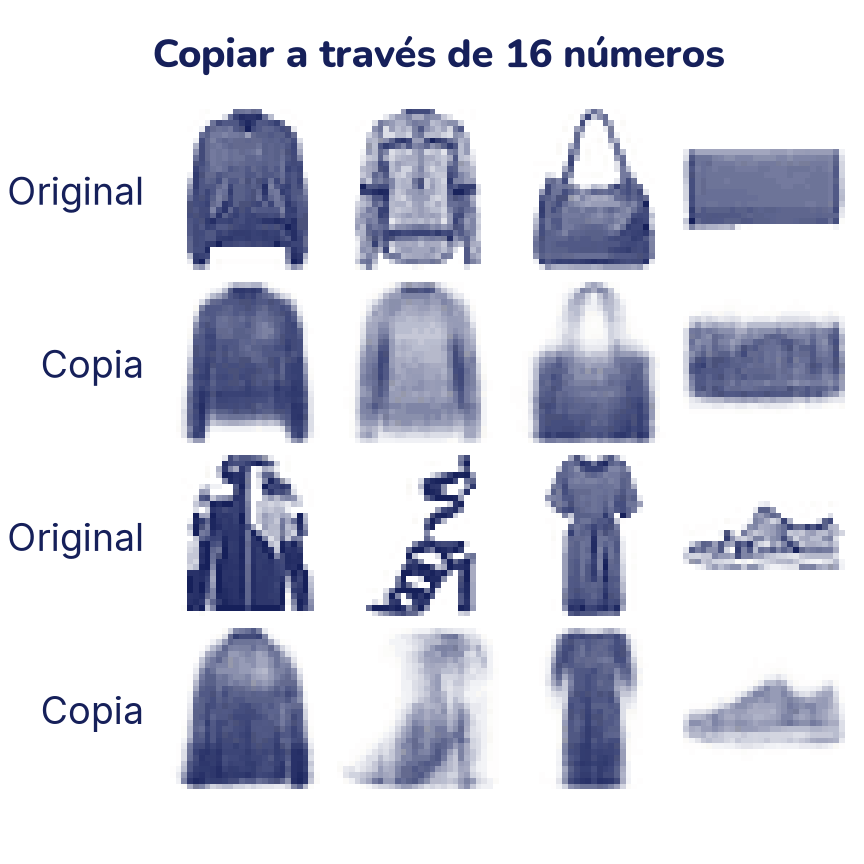

In [ ]:
ae.eval()
with torch.no_grad():
    muestra = x_val[:8]
    copia = ae(muestra.to(device)).cpu()

# Filas alternadas: 4 originales, sus 4 copias, otras 4 y sus copias
filas = [muestra[:4], copia[:4], muestra[4:], copia[4:]]
lote = torch.cat(filas).view(-1, 1, 28, 28)
mosaico = make_grid(lote, nrow=4, padding=2, pad_value=0)
plt.figure(figsize=(4.8, 4.8))
plt.imshow(mosaico[0], cmap=tinta)
plt.yticks([15, 45, 75, 105], ["Original", "Copia", "Original", "Copia"])
plt.xticks([])
plt.grid(False)
plt.box(False)                # sin el marco de los ejes
plt.tick_params(length=0)     # ni las marquitas junto a los rótulos
plt.title("Copiar a través de 16 números")
plt.show()

Las reconstrucciones conservan la forma y el tono, pero salen **borrosas**: se pierden los estampados, las rayas y las costuras. Es lo esperable. Con 16 números no cabe todo, y el error cuadrático premia «quedarse en el medio» cuando la red no está segura de un detalle: el promedio de varios estampados posibles es una mancha gris. Mira la sandalia: sus tiras finas se perdieron y la copia parece un botín borroso. Las sandalias son pocas y muy variadas, y al autoencoder le conviene más copiar bien las prendas comunes.

### El espacio latente: caminar entre dos prendas

Los 16 números de cada prenda son un punto en un **espacio latente** de 16 dimensiones, la misma idea de los mapas del tema 15 y de los embeddings del tema 22. Las prendas parecidas quedan cerca. Y como el decodificador convierte **cualquier** punto de ese espacio en una imagen, podemos pedirle imágenes de puntos que no vienen de ninguna prenda real.

Tomemos dos parejas de prendas, un pantalón y un vestido, y una zapatilla y un botín, y hagamos dos caminos de una a otra, en siete pasos:

- **mezclar píxeles**: promediar las dos imágenes con pesos 1 − *a* y *a*;
- **mezclar en el espacio latente**: promediar sus dos códigos *z* con los mismos pesos y decodificar.

Códigos del camino: (7, 16)


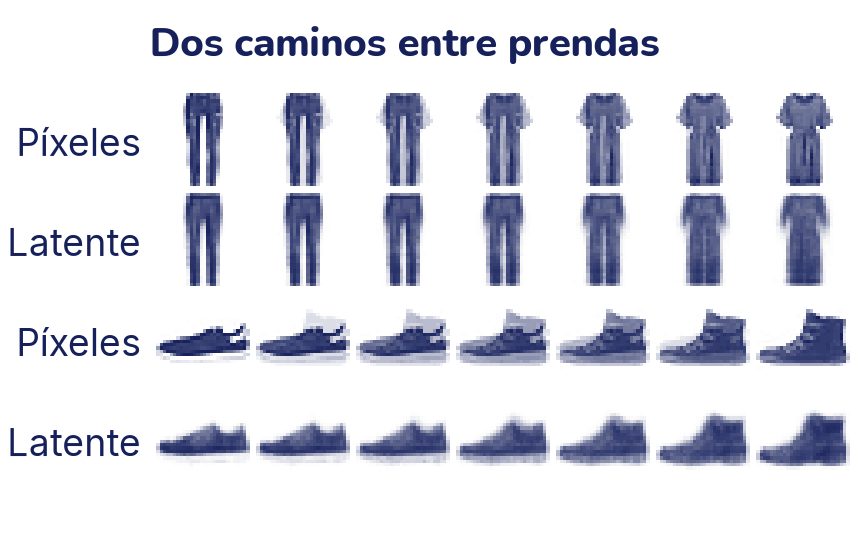

In [ ]:
def codigo(x):
    with torch.no_grad():
        return ae.codificador(x.to(device))


def decodificar(z):
    with torch.no_grad():
        return ae.decodificador(z).cpu()


def primera(clase):
    """La primera prenda de esa clase en la validación."""
    return x_val[(y_val == clase).nonzero()[0, 0]]


pesos = torch.linspace(0, 1, 7).unsqueeze(1)          # (7, 1)
filas = []
# Pantalón -> vestido y zapatilla -> botín
for a_img, b_img in [(primera(1), primera(3)), (primera(7), primera(9))]:
    z_a, z_b = codigo(a_img), codigo(b_img)
    filas.append((1 - pesos) * a_img + pesos * b_img)
    filas.append(decodificar((1 - pesos) * z_a + pesos * z_b))
print("Códigos del camino:", tuple(((1 - pesos) * z_a).shape))

lote = torch.cat(filas).view(-1, 1, 28, 28)
mosaico = make_grid(lote, nrow=7, padding=2, pad_value=0)
# Más baja que la de siempre: el mosaico es mucho más ancho que alto
plt.figure(figsize=(4.8, 3))
plt.imshow(mosaico[0], cmap=tinta)
plt.yticks([15, 45, 75, 105], ["Píxeles", "Latente", "Píxeles", "Latente"])
plt.xticks([])
plt.grid(False)
plt.box(False)                # sin el marco de los ejes
plt.tick_params(length=0)     # ni las marquitas junto a los rótulos
plt.title("Dos caminos entre prendas")
plt.show()

En las filas «Píxeles», el camino da **dos prendas transparentes encimadas**: las imágenes del medio no parecen ninguna prenda de verdad. En las filas «Latente», cada paso es **una sola forma** que se transforma: el pantalón se ensancha hasta ser vestido y la zapatilla le crece la caña. El espacio latente ordenó las prendas de modo que los puntos intermedios también decodifican en algo con sentido (aunque sea borroso, como todas las copias de este autoencoder). Pero eso funciona en el camino entre dos prendas reales, y solo a veces fuera de esos caminos.

Ese «a veces» es el problema del autoencoder como generador: si eliges un punto **al azar** en el espacio latente, lo más probable es que caiga en una zona por donde no pasó ninguna prenda, y el decodificador devuelve una mancha. El **autoencoder variacional** (VAE) resuelve eso obligando a que los códigos se repartan como una nube gaussiana ordenada; así, cualquier punto sacado de esa nube decodifica en una prenda creíble. No lo programamos aquí, pero es la misma estructura de codificador y decodificador con una pérdida extra.

## GANs: el falsificador y el detective

Una **GAN** (red generativa antagónica) pone a dos redes a competir:

- El **generador** *G* recibe ruido al azar *z* y produce un dato falso, *G*(*z*). Nunca ve los datos reales.
- El **discriminador** *D* recibe un dato y devuelve la probabilidad de que sea real. Es un clasificador binario como la regresión logística del tema 8.

El discriminador entrena para acertar: decir 1 a los reales y 0 a los falsos. El generador entrena para engañarlo: que *D* le diga 1 a sus falsos. Las dos pérdidas son la entropía cruzada binaria, con los objetivos al revés:

$${L}_{D} = - \log D ( x ) - \log ( 1 - D ( G ( z ) ) )$$

$${L}_{G} = - \log D ( G ( z ) )$$

Por eso se le dice **pérdida adversarial**: lo que mejora a uno empeora al otro. Si los dos juegan perfecto, el generador produce datos indistinguibles de los reales y el discriminador ya no puede hacer nada mejor que decir 0,5 a todo. En ese punto, *L*<sub>D</sub> vale 2 · log 2 ≈ 1,386 y *L*<sub>G</sub> vale log 2 ≈ 0,693.

### Una GAN que aprende un anillo

Empecemos con datos de dos dimensiones, para poder ver todo. Los datos reales son puntos sobre un **anillo** de radio 2; el generador recibe dos números al azar y tiene que devolver un punto que parezca del anillo.

En cada paso, primero entrena el discriminador con un lote de reales y uno de falsos, y después el generador. Ojo con el `detach()`: al entrenar el discriminador, los falsos son solo datos; no queremos que ese paso mueva al generador.

In [ ]:
def anillo(n):
    """Puntos reales: un anillo de radio 2, un poco borroso."""
    angulo = torch.rand(n) * 2 * torch.pi
    radio = 2 + 0.1 * torch.randn(n)
    return torch.stack([radio * torch.cos(angulo),
                        radio * torch.sin(angulo)], dim=1)


torch.manual_seed(0)
generador = nn.Sequential(nn.Linear(2, 64), nn.ReLU(),
                          nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 2))
discriminador = nn.Sequential(nn.Linear(2, 64), nn.ReLU(),
                              nn.Linear(64, 64), nn.ReLU(),
                              nn.Linear(64, 1))     # da un logit
# betas=(0.5, ...): Adam recuerda menos los gradientes viejos, lo
# habitual en GANs (no son los β del programa de ruido de más abajo)
opt_g = torch.optim.Adam(generador.parameters(), lr=1e-3,
                         betas=(0.5, 0.999))
opt_d = torch.optim.Adam(discriminador.parameters(), lr=1e-3,
                         betas=(0.5, 0.999))
bce = nn.BCEWithLogitsLoss()          # entropía cruzada binaria
unos, ceros = torch.ones(256, 1), torch.zeros(256, 1)

z_fijo = torch.randn(1000, 2)         # el mismo ruido para cada foto
fotos, perdidas_d, perdidas_g = {}, [], []
for paso in range(5001):
    if paso in (0, 500, 5000):
        with torch.no_grad():
            fotos[paso] = generador(z_fijo)
    if paso == 5000:
        break
    real = anillo(256)
    falso = generador(torch.randn(256, 2))
    # 1) El discriminador: 1 a los reales, 0 a los falsos
    perdida_d = (bce(discriminador(real), unos)
                 + bce(discriminador(falso.detach()), ceros))
    opt_d.zero_grad()
    perdida_d.backward()
    opt_d.step()
    # 2) El generador: que el discriminador diga 1 a sus falsos
    perdida_g = bce(discriminador(falso), unos)
    opt_g.zero_grad()
    perdida_g.backward()
    opt_g.step()
    perdidas_d.append(perdida_d.item())
    perdidas_g.append(perdida_g.item())

with torch.no_grad():
    radios = fotos[5000].norm(dim=1)
    d_real = torch.sigmoid(discriminador(anillo(1000))).mean()
    d_falso = torch.sigmoid(discriminador(fotos[5000])).mean()
print(f"Radio de los puntos generados: {radios.mean():.2f} "
      f"± {radios.std():.2f}")
print(f"D promedio: reales {d_real:.2f}, falsos {d_falso:.2f}")

Radio de los puntos generados: 2.00 ± 0.11
D promedio: reales 0.50, falsos 0.50


El generador aprendió a poner sus puntos a distancia 2 del centro, y el discriminador termina diciendo casi lo mismo a reales y falsos, cerca de 0,5. Veamos cómo llegó ahí.

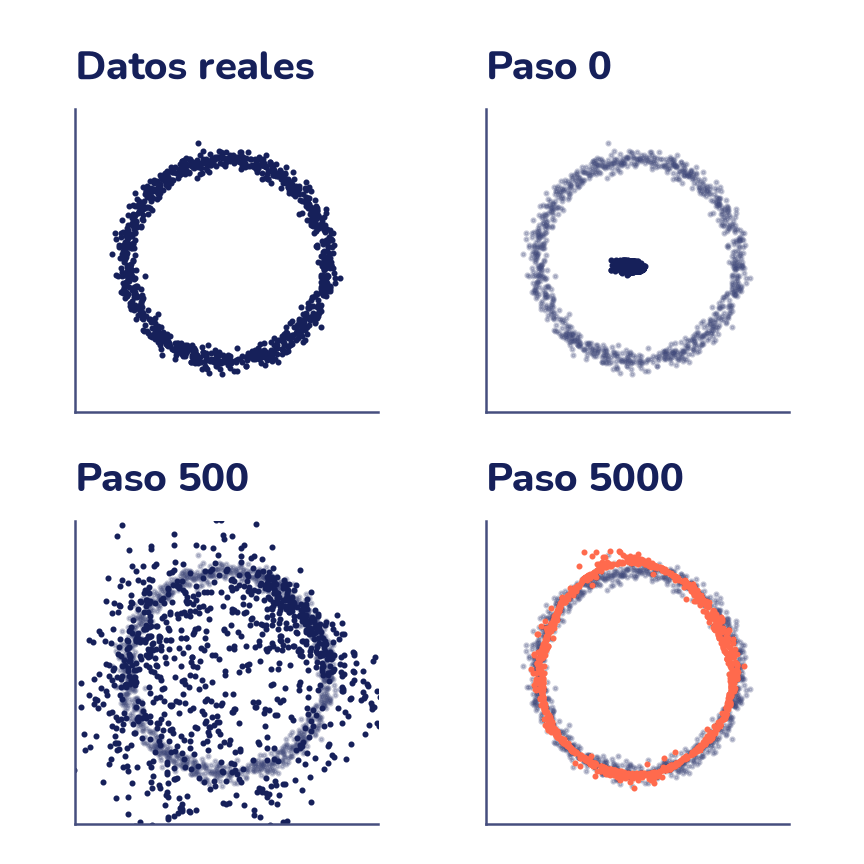

In [ ]:
fig, ejes = plt.subplots(2, 2, figsize=(4.8, 4.8))
reales = anillo(1000)
paneles = [("Datos reales", reales, "C0"),
           ("Paso 0", fotos[0], "C0"),
           ("Paso 500", fotos[500], "C0"),
           ("Paso 5000", fotos[5000], "C1")]
for eje, (titulo, puntos, color) in zip(ejes.flat, paneles):
    if titulo != "Datos reales":
        eje.scatter(reales[:, 0], reales[:, 1], s=2, color="C2",
                    alpha=0.3)
    eje.scatter(puntos[:, 0], puntos[:, 1], s=2, color=color)
    eje.set_title(titulo)
    eje.set_xlim(-3, 3)
    eje.set_ylim(-3, 3)
    eje.set_aspect("equal")
    eje.set_xticks([])
    eje.set_yticks([])
plt.tight_layout()
plt.show()

Antes de entrenar, el generador saca una mancha chica en el centro: todavía no sabe nada. A los 500 pasos muchos puntos ya están sobre el anillo, pero otros siguen desparramados; a los 5000 el anillo está completo y fino. Las pérdidas cuentan la misma historia:

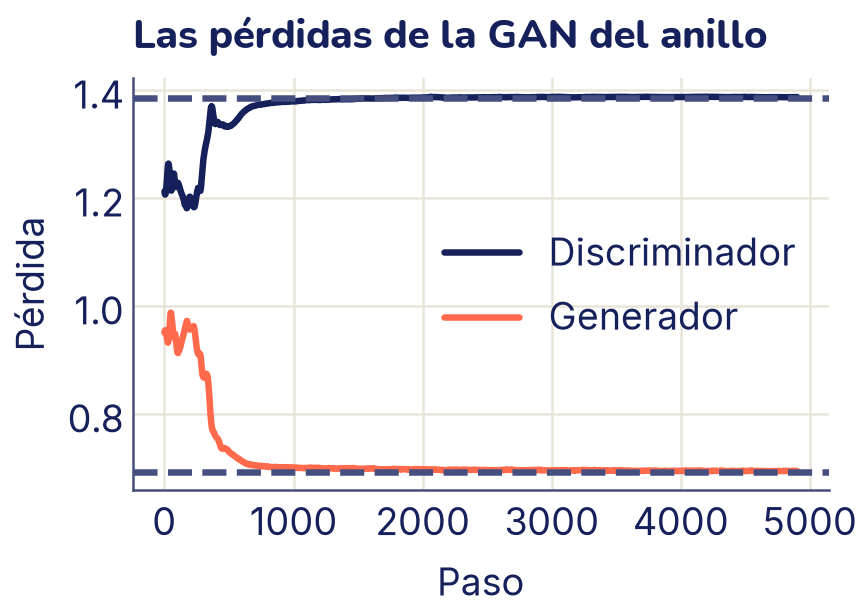

In [ ]:
def suavizar(valores, ventana=100):
    """Promedio móvil: cada punto es la media de 100 pasos."""
    return np.convolve(valores, np.ones(ventana) / ventana, mode="valid")


plt.plot(suavizar(perdidas_d), color="C0", label="Discriminador")
plt.plot(suavizar(perdidas_g), color="C1", label="Generador")
plt.axhline(2 * np.log(2), color="C2", linestyle="--")
plt.axhline(np.log(2), color="C2", linestyle="--")
plt.xlabel("Paso")
plt.ylabel("Pérdida")
plt.title("Las pérdidas de la GAN del anillo")
plt.legend()
plt.show()

En una GAN **las pérdidas no bajan hasta cero** como en todos los modelos anteriores: aquí se estabilizan en las líneas punteadas, 2 · log 2 y log 2, los valores del empate. Y una pérdida del generador más baja no siempre quiere decir mejores muestras, porque depende de qué tan bueno es el discriminador en ese momento. Por eso, para juzgar una GAN, hay que **mirar sus muestras**.

### Inestabilidad y colapso de modos

Este anillo salió bien, pero entrenar GANs tiene fama de difícil:

- **Inestabilidad.** Cada red persigue un blanco que se mueve: el generador mejora contra el discriminador de ahora, que en el paso siguiente ya cambió. Las pérdidas pueden oscilar sin asentarse, y una tasa de aprendizaje un poco alta puede desarmar todo.
- **Colapso de modos.** El generador puede encontrar un tipo de dato que engaña bien al discriminador y producir solo ese: siempre el mismo dígito, siempre el mismo pedazo del anillo. Los datos tienen varios «modos» (zonas con muchos ejemplos) y el generador cubre solo uno o unos pocos. En la actividad lo viste en pequeño: en el paso 2500 el generador se encogió y producía casi siempre el mismo valor.

Para detectar un colapso no basta con mirar una muestra bonita: hay que mirar **muchas** y preguntarse si están todas las variedades de los datos reales. Lo vas a hacer en el ejercicio 3.

### Una GAN que escribe dígitos

Ahora una GAN de verdad, con imágenes: los 60 000 dígitos escritos a mano de **MNIST** (LeCun, Cortes y Burges; licencia MIT según la ficha de Hugging Face del dataset). El generador recibe 64 números al azar y devuelve 784 píxeles; el discriminador recibe 784 píxeles y da un logit. Las dos son MLP, con `LeakyReLU`, que deja pasar un poco de los valores negativos (ayuda a que al discriminador le lleguen gradientes). Los píxeles van de −1 a 1, y por eso la última capa del generador es `Tanh`.

Son 20 épocas: con 2 núcleos (hilos) del procesador, como un Colab sin GPU, tardó menos de un minuto en la computadora donde se preparó este tema.

In [ ]:
# La primera vez descarga unos 11 MB; después queda en «datos»
mnist = datasets.MNIST(root="datos", train=True, download=True)
# Píxeles de -1 a 1, aplanados
x_mnist = mnist.data.float().div(255).mul(2).sub(1).view(-1, 784)

torch.manual_seed(0)
ruido_dim = 64
gen_dig = nn.Sequential(
    nn.Linear(ruido_dim, 256), nn.LeakyReLU(0.2),
    nn.Linear(256, 512), nn.LeakyReLU(0.2),
    nn.Linear(512, 784), nn.Tanh()).to(device)
dis_dig = nn.Sequential(
    nn.Linear(784, 512), nn.LeakyReLU(0.2),
    nn.Linear(512, 256), nn.LeakyReLU(0.2),
    nn.Linear(256, 1)).to(device)
opt_g = torch.optim.Adam(gen_dig.parameters(), lr=2e-4, betas=(0.5, 0.999))
opt_d = torch.optim.Adam(dis_dig.parameters(), lr=2e-4, betas=(0.5, 0.999))
cargador = DataLoader(TensorDataset(x_mnist), batch_size=128, shuffle=True,
                      drop_last=True,
                      generator=torch.Generator().manual_seed(0))

for epoca in range(1, 21):
    suma_d = suma_g = 0.0
    for (real,) in cargador:
        real = real.to(device)
        n = len(real)
        unos = torch.ones(n, 1, device=device)
        ceros = torch.zeros(n, 1, device=device)
        falso = gen_dig(torch.randn(n, ruido_dim, device=device))
        perdida_d = (bce(dis_dig(real), unos)
                     + bce(dis_dig(falso.detach()), ceros))
        opt_d.zero_grad()
        perdida_d.backward()
        opt_d.step()
        perdida_g = bce(dis_dig(falso), unos)
        opt_g.zero_grad()
        perdida_g.backward()
        opt_g.step()
        suma_d += perdida_d.item()
        suma_g += perdida_g.item()
    if epoca % 5 == 0:
        print(f"Época {epoca}: pérdida D {suma_d / len(cargador):.3f}, "
              f"G {suma_g / len(cargador):.3f}")

Época 5: pérdida D 0.673, G 2.341
Época 10: pérdida D 0.688, G 2.212
Época 15: pérdida D 0.820, G 1.852
Época 20: pérdida D 0.940, G 1.504


In [ ]:
with torch.no_grad():
    digitos = gen_dig(torch.randn(36, ruido_dim, device=device)).cpu()
digitos = digitos.add(1).div(2).view(-1, 1, 28, 28)   # de vuelta a 0..1
mosaico = make_grid(digitos, nrow=6, padding=2, pad_value=0)
plt.figure(figsize=(4.8, 4.8))
plt.imshow(mosaico[0], cmap=tinta)
plt.axis("off")
plt.title("36 dígitos que no escribió nadie")
plt.show()

Aquí las pérdidas no llegan al empate: el discriminador sigue ganando (su pérdida está por debajo de 1,386 y la del generador, por encima de 0,693). El generador todavía no lo engaña del todo, pero la distancia se acorta época a época. Miremos las muestras.

Muchos se reconocen, otros son garabatos, y casi todos tienen puntitos sueltos: un MLP no sabe que los píxeles vecinos se parecen. Las GANs que generan caras realistas usan generadores convolucionales (con capas que agrandan la imagen paso a paso, la versión al revés de la CNN del tema 20) y muchas horas de GPU. Con una GAN convolucional pequeña los dígitos salen más limpios, pero en CPU cada época tarda más de un minuto; por eso aquí usamos un MLP.

## Difusión: añadir ruido y aprender a quitarlo

La difusión parte de una idea muy simple. **Destruir** una imagen es fácil: le sumas un poco de ruido, y otro poco, y otro, hasta que solo queda ruido. Lo difícil es el camino de vuelta. Un modelo de difusión aprende justamente eso: **mirar un dato con ruido y adivinar qué ruido tiene encima**. Si sabe adivinarlo, se lo puede restar de a poco. Y si empieza desde ruido puro, al restarlo todo aparece un dato nuevo.

### La ida: el programa de ruido

La ida no se aprende: es una receta fija de *T* pasos. En cada paso *t* se **achica un poco el dato y se suma un poco de ruido** gaussiano. Cuánto ruido se suma lo dice un número β<sub>t</sub> (su varianza), y la lista β<sub>1</sub>, …, β<sub>T</sub> se llama **programa de ruido**. En fórmula, un paso es x<sub>t</sub> = √(1 − β<sub>t</sub>) · x<sub>t−1</sub> + √β<sub>t</sub> · ε, con ε un ruido nuevo de N(0, 1).

¿Por qué las raíces? Porque así los cuadrados de los dos coeficientes suman 1: (√(1 − β<sub>t</sub>))² + (√β<sub>t</sub>)² = 1, como los dos catetos de un triángulo rectángulo cuya hipotenusa mide 1 (el teorema de Pitágoras). Si el dato tiene varianza 1, después del paso la sigue teniendo: lo que pierde la señal lo gana el ruido, y la nube no se agranda sin fin. Aquí usamos *T* = 100 y β crece en línea recta de 0,0001 a 0,1: al principio se agrega poco ruido y al final mucho.

No hace falta aplicar los pasos uno por uno. Si α<sub>t</sub> = 1 − β<sub>t</sub> y ᾱ<sub>t</sub> es el producto de α<sub>1</sub> hasta α<sub>t</sub>, multiplicando todos los pasos el dato en el paso *t* sale de un solo golpe:

$${x}_{t} = \sqrt{{\overline{\alpha}}_{t}} \; {x}_{0} + \sqrt{1 - {\overline{\alpha}}_{t}} \; \varepsilon \qquad \varepsilon \sim \mathcal{N} ( 0 , 1 )$$

Es una mezcla: √ᾱ<sub>t</sub> de dato y √(1 − ᾱ<sub>t</sub>) de ruido, y otra vez los cuadrados de las dos cifras suman 1. Con *t* = 0 todo es dato; con *t* = *T*, casi todo es ruido. Son las dos cifras que veías en la actividad.

Usamos la espiral de la actividad: 2000 puntos sintéticos generados con una fórmula.

t =   0: señal 1.00, ruido 0.00
t =  10: señal 0.98, ruido 0.21
t =  20: señal 0.91, ruido 0.42
t =  50: señal 0.53, ruido 0.85
t = 100: señal 0.07, ruido 1.00


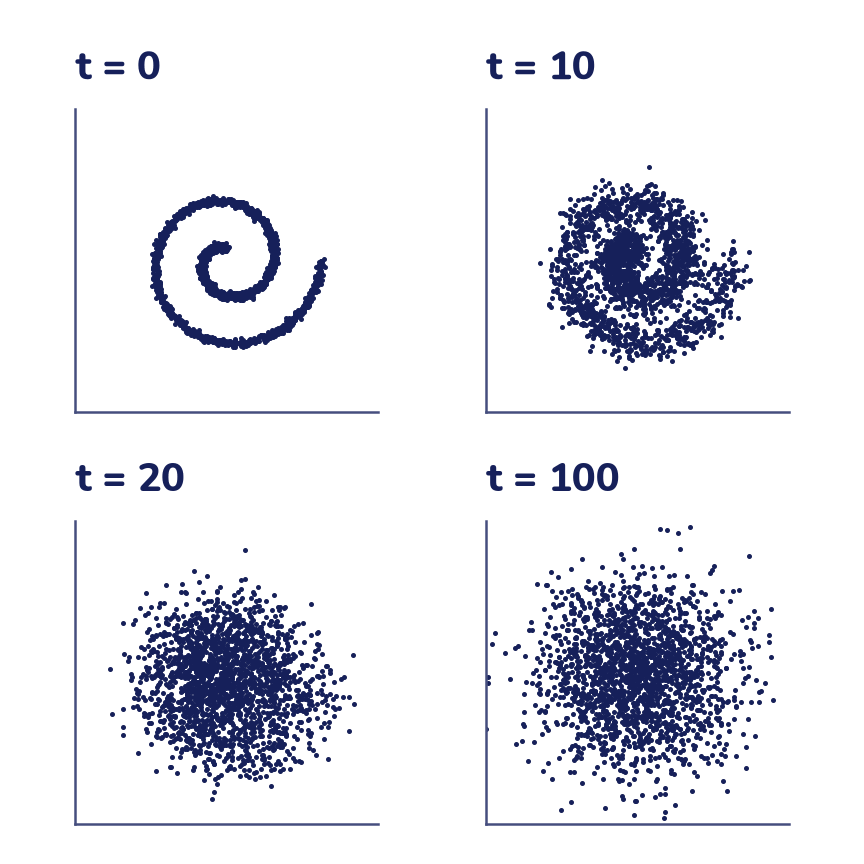

In [ ]:
rng = np.random.default_rng(42)


def espiral(n):
    """Puntos sobre una espiral de dos vueltas, con un poco de ruido."""
    angulo = rng.uniform(np.pi / 2, 4 * np.pi, n)
    radio = angulo / (2 * np.pi)
    xy = np.stack([radio * np.cos(angulo), radio * np.sin(angulo)], axis=1)
    xy += rng.normal(0, 0.04, size=(n, 2))
    return torch.tensor(xy, dtype=torch.float32)


datos_2d = espiral(2000)

T = 100
# beta[0] = 0: el paso 0 son los datos sin ruido
beta = torch.cat([torch.zeros(1), torch.linspace(1e-4, 0.1, T)])
alfa = 1 - beta
alfa_barra = torch.cumprod(alfa, dim=0)


def agregar_ruido(x0, t, eps):
    """La ida en un solo golpe: x_t a partir de x_0 y el ruido eps."""
    ab = alfa_barra[t].view(-1, 1)
    return ab.sqrt() * x0 + (1 - ab).sqrt() * eps


for t in [0, 10, 20, 50, 100]:
    print(f"t = {t:3d}: señal {alfa_barra[t].sqrt():.2f}, "
          f"ruido {(1 - alfa_barra[t]).sqrt():.2f}")

eps = torch.randn_like(datos_2d)
fig, ejes = plt.subplots(2, 2, figsize=(4.8, 4.8))
for eje, t in zip(ejes.flat, [0, 10, 20, 100]):
    xt = agregar_ruido(datos_2d, torch.full((2000,), t), eps)
    eje.scatter(xt[:, 0], xt[:, 1], s=1, color="C0")
    eje.set_title(f"t = {t}")
    eje.set_xlim(-3.2, 3.2)
    eje.set_ylim(-3.2, 3.2)
    eje.set_aspect("equal")
    eje.set_xticks([])
    eje.set_yticks([])
plt.tight_layout()
plt.show()

La espiral se borra muy pronto: en *t* = 20 todavía queda el 91 % de la señal, pero el ruido (0,42) ya es casi tan grande como la distancia entre dos brazos de la espiral, que es de 0,5, y la forma desaparece. Con este programa lineal, más de las tres cuartas partes de los pasos trabajan sobre una nube donde ya no se ve la espiral. El programa de ruido es una decisión de diseño; en el ejercicio 4 comparas dos.

### La vuelta: una red que adivina el ruido

Ahora lo que se aprende. La red recibe un punto con ruido *x*<sub>t</sub> y el paso *t*, y devuelve su estimación del ruido, ε̂. Para entrenarla, en cada lote:

1. elegimos datos *x*<sub>0</sub>, pasos *t* al azar entre 1 y *T*, y ruido ε;
2. fabricamos *x*<sub>t</sub> con la fórmula de la ida;
3. le pedimos a la red que adivine ε, y la pérdida es el error cuadrático entre ε y ε̂.

$$L = \text{promedio de} \; {( \varepsilon - {\hat{\varepsilon}}_{\theta} ( {x}_{t} , t ) )}^{2}$$

Es aprendizaje supervisado común y corriente, con una trampa a favor: las respuestas correctas (el ruido) las fabricamos nosotros, así que hay infinitos ejemplos. Como la misma red trabaja en todos los pasos, tiene que saber en cuál está: le pasamos *t* convertido en 16 números (senos y cosenos de *t* a varias frecuencias, la misma idea de las posiciones del transformer en el tema 23).

In [ ]:
def incrustar(t):
    """Codifica el paso t con senos y cosenos de 8 frecuencias."""
    frecuencias = 2.0 ** torch.arange(8)
    a = t.float().unsqueeze(1) / T * torch.pi * frecuencias
    return torch.cat([a.sin(), a.cos()], dim=1)


torch.manual_seed(0)
# SiLU: una ReLU suave, x · sigmoide(x)
red = nn.Sequential(nn.Linear(2 + 16, 128), nn.SiLU(),
                    nn.Linear(128, 128), nn.SiLU(),
                    nn.Linear(128, 128), nn.SiLU(),
                    nn.Linear(128, 2))         # el ruido estimado
pasos = 15000
optimizador = torch.optim.Adam(red.parameters(), lr=2e-3)
# Programador de tasa (tema 19): la tasa baja suavemente hasta 0
programador = torch.optim.lr_scheduler.CosineAnnealingLR(optimizador,
                                                         pasos)
perdidas = []
for paso in range(pasos):
    x0 = datos_2d[torch.randint(0, 2000, (512,))]
    t = torch.randint(1, T + 1, (512,))
    eps = torch.randn_like(x0)
    xt = agregar_ruido(x0, t, eps)
    eps_estimado = red(torch.cat([xt, incrustar(t)], dim=1))
    perdida = ((eps_estimado - eps) ** 2).mean()
    optimizador.zero_grad()
    perdida.backward()
    optimizador.step()
    programador.step()
    perdidas.append(perdida.item())

print(f"Pérdida media, primeros 500 pasos: {np.mean(perdidas[:500]):.3f}")
print(f"Pérdida media, últimos 500 pasos:  {np.mean(perdidas[-500:]):.3f}")

Pérdida media, primeros 500 pasos: 0.374
Pérdida media, últimos 500 pasos:  0.307


La pérdida no llega a cero, y no puede: con *t* grande, el dato está tan tapado que nadie puede adivinar exactamente qué ruido tiene. Lo que importa es que la red adivine lo mejor posible en promedio.

Para **muestrear** empezamos con ruido puro y vamos de *t* = *T* a *t* = 1. En cada paso restamos una parte del ruido estimado y, salvo en el último, volvemos a sumar un poco de ruido nuevo (eso evita que todos los puntos caigan en el mismo lugar):

$${x}_{t - 1} = \frac{1}{\sqrt{{\alpha}_{t}}} ( {x}_{t} - \frac{{\beta}_{t}}{\sqrt{1 - {\overline{\alpha}}_{t}}} {\hat{\varepsilon}}_{\theta} ( {x}_{t} , t ) ) + \sqrt{{\beta}_{t}} \; \xi$$

Pieza por pieza: dentro del paréntesis restamos la parte del ruido estimado ε̂<sub>θ</sub> que corresponde a este paso; el 1/√α<sub>t</sub> deshace el encogimiento de la ida, y √β<sub>t</sub> ξ suma un poco de ruido fresco, con ξ (la letra griega «xi») sacado de N(0, 1) en cada paso. Usamos ξ y no *z* para no confundirlo con el código latente del autoencoder ni con el ruido de entrada de la GAN.

Este es el muestreo **DDPM** (*Denoising Diffusion Probabilistic Models*, Ho, Jain y Abbeel, 2020). Guardamos la nube en algunos pasos para ver la vuelta:

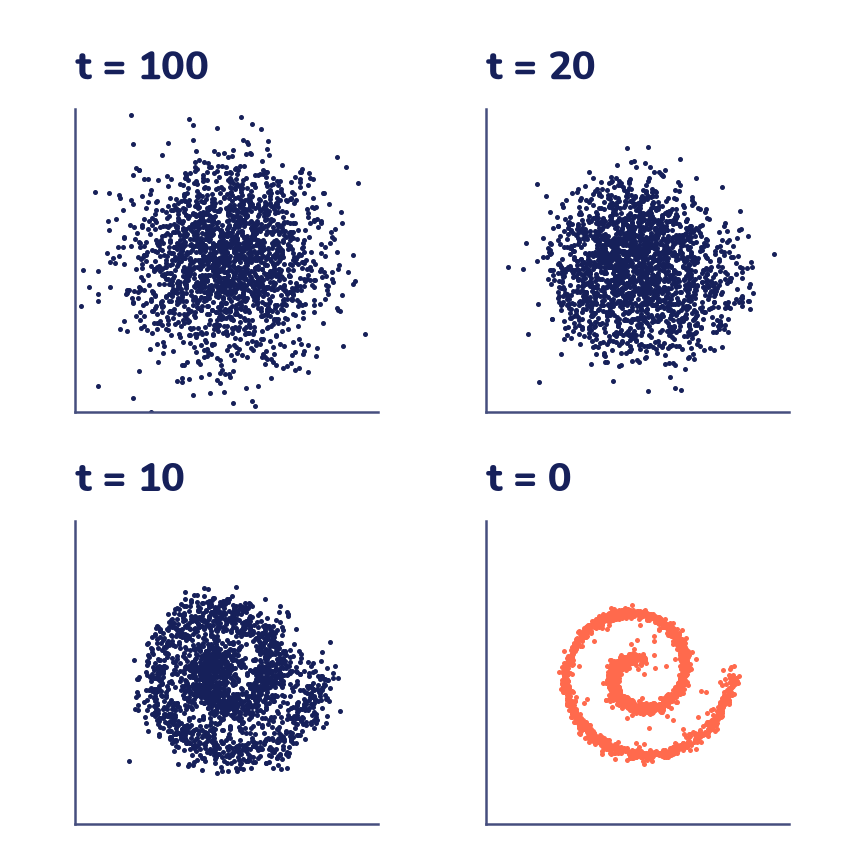

In [ ]:
@torch.no_grad()
def muestrear(n, guardar=(100, 20, 10, 0)):
    x = torch.randn(n, 2)                 # ruido puro: el paso T
    fotos = {T: x.clone()}
    for t in range(T, 0, -1):
        tt = torch.full((n,), t)
        e = red(torch.cat([x, incrustar(tt)], dim=1))
        x = (x - beta[t] / (1 - alfa_barra[t]).sqrt() * e) / alfa[t].sqrt()
        if t > 1:
            x = x + beta[t].sqrt() * torch.randn_like(x)
        if t - 1 in guardar:
            fotos[t - 1] = x.clone()
    return fotos


torch.manual_seed(1)
vuelta = muestrear(2000)
fig, ejes = plt.subplots(2, 2, figsize=(4.8, 4.8))
for eje, t in zip(ejes.flat, [100, 20, 10, 0]):
    color = "C1" if t == 0 else "C0"
    eje.scatter(vuelta[t][:, 0], vuelta[t][:, 1], s=1, color=color)
    eje.set_title(f"t = {t}")
    eje.set_xlim(-3.2, 3.2)
    eje.set_ylim(-3.2, 3.2)
    eje.set_aspect("equal")
    eje.set_xticks([])
    eje.set_yticks([])
plt.tight_layout()
plt.show()

La vuelta es la ida al revés: la mancha se va achicando y la espiral aparece recién en los últimos 10 o 20 pasos, justo los pasos de la ida donde se había borrado. ¡Del ruido sale una espiral!
 No es ninguna de las 2000 espirales de los datos punto por punto: son 2000 puntos **nuevos** que siguen la misma forma. Algunos quedan sueltos entre los brazos; con más pasos de entrenamiento o una red más grande serían menos. Es exactamente lo que hacía el botón «Reconstruir» de la actividad.

El modelo de difusión tiene ventajas claras sobre la GAN: se entrena con una pérdida simple que baja de forma estable (no hay un juego entre dos redes) y no tiende a colapsar en un solo modo, porque la red se entrena con todos los datos reales, de todas las zonas, y nadie la premia por quedarse en una sola; el generador de una GAN solo necesita engañar al discriminador. Su desventaja es la velocidad: para crear una sola muestra hay que evaluar la red *T* veces.

## Un modelo de difusión preentrenado

La misma idea, con imágenes. El modelo [`google/ddpm-cifar10-32`](https://huggingface.co/google/ddpm-cifar10-32) (licencia Apache-2.0) es el de Ho, Jain y Abbeel (2020): una red U-Net de 35,7 millones de parámetros que predice el ruido de imágenes en color de 32 × 32. Se entrenó con *T* = 1000 pasos sobre CIFAR-10 (Krizhevsky, 2009), 60 000 fotos chicas de aviones, autos, pájaros, gatos, ciervos, perros, ranas, caballos, barcos y camiones. La U-Net es una CNN con forma de codificador-decodificador: achica la imagen para ver el conjunto y la vuelve a agrandar para devolver el ruido píxel a píxel.

La biblioteca `diffusers` lo carga con su ***scheduler***, la pieza que guarda el programa de ruido y decide cómo dar los pasos de la vuelta (no confundir con el programador de tasa del tema 19, que en inglés también se llama *scheduler*). El muestreo original usa los 1000 pasos: las imágenes salen limpias, pero en CPU cada imagen tarda más de medio minuto. ¿Qué pasa si damos solo 50?

Probamos dos *schedulers*, es decir, dos formas de dar la vuelta, con **la misma red y la misma semilla**:

- **DDPM** con 50 pasos: la receta de arriba, pero saltando de 20 en 20 pasos.
- **DDIM** (Song, Meng y Ermon, 2020): reescribe la vuelta para que sea **determinista** (no agrega ruido nuevo en cada paso) y aguanta saltos grandes sin perder calidad.

Parámetros de la U-Net: 35,746,307
Pasos con que se entrenó: 1000
Forma: (4, 32, 32, 3)  valores entre 0 y 1


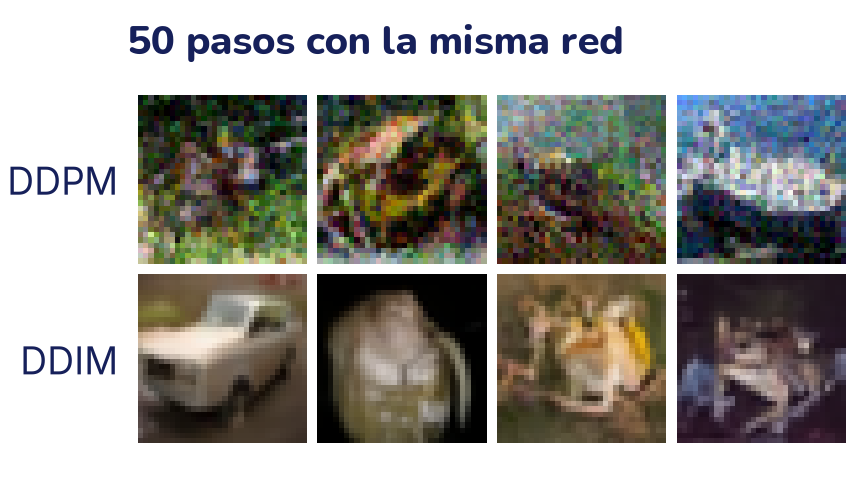

In [ ]:
from diffusers import DDPMPipeline, DDIMPipeline, DDIMScheduler

# La primera vez descarga unos 143 MB
ddpm = DDPMPipeline.from_pretrained("google/ddpm-cifar10-32")
ddpm.set_progress_bar_config(disable=True)
ddim = DDIMPipeline(unet=ddpm.unet,
                    scheduler=DDIMScheduler.from_config(
                        ddpm.scheduler.config))
ddim.set_progress_bar_config(disable=True)
print("Parámetros de la U-Net:",
      f"{sum(p.numel() for p in ddpm.unet.parameters()):,}")
print("Pasos con que se entrenó:", ddpm.scheduler.config.num_train_timesteps)

g = torch.Generator().manual_seed(0)
imgs_ddpm = ddpm(batch_size=4, num_inference_steps=50, generator=g,
                 output_type="np").images            # (4, 32, 32, 3)
g = torch.Generator().manual_seed(0)
imgs_ddim = ddim(batch_size=4, num_inference_steps=50, generator=g,
                 output_type="np").images
print("Forma:", imgs_ddpm.shape, " valores entre 0 y 1")

# Cuatro de DDPM arriba y cuatro de DDIM abajo
lote = torch.tensor(np.concatenate([imgs_ddpm, imgs_ddim]))
mosaico = make_grid(lote.permute(0, 3, 1, 2), nrow=4, padding=2,
                    pad_value=1)
# Más baja que la de siempre: el mosaico es el doble de ancho que de alto
plt.figure(figsize=(4.8, 2.8))
plt.imshow(mosaico.permute(1, 2, 0))
plt.yticks([17, 51], ["DDPM", "DDIM"])
plt.xticks([])
plt.grid(False)
plt.box(False)                # sin el marco de los ejes
plt.tick_params(length=0)     # ni las marquitas junto a los rótulos
plt.title("50 pasos con la misma red")

plt.show()

Arriba, DDPM con 50 pasos deja las imágenes **llenas de ruido**: su receta está pensada para 1000 pasos chicos, y con saltos de 20 no alcanza a limpiar. Abajo, con la misma red y el mismo ruido inicial, DDIM da imágenes **limpias**: un auto, ranas, una figura sobre fondo oscuro. Las formas se parecen arriba y abajo porque parten del mismo ruido. Son imágenes de 32 × 32, así que se ven borrosas al agrandarlas, y algunas no son nada claro; así son las muestras de este modelo.

Este es el **compromiso entre pasos y calidad**. Más pasos dan mejores imágenes pero tardan más, porque cada paso es una pasada completa de la U-Net. Medido en la computadora donde se preparó este tema (CPU, 2 hilos): 4 imágenes con 50 pasos tardan unos 5 segundos con cualquiera de los dos programadores, y con los 1000 pasos de DDPM, unos 100 segundos. Buena parte de la investigación en difusión busca dar menos pasos sin perder calidad.

## Modelos grandes, guía por texto y uso responsable

Los generadores de imágenes que conoces (Stable Diffusion, Midjourney, DALL·E, Imagen y otros) usan estas mismas ideas, con tres agregados:

- **Difusión en un espacio latente.** En vez de quitar ruido a millones de píxeles, un autoencoder comprime la imagen a un código más chico y la difusión trabaja ahí; al final, el decodificador vuelve a los píxeles. Es la idea de Stable Diffusion (difusión latente).
- **Guía por texto.** La red que estima el ruido recibe también el embedding de una frase, calculado por un codificador de texto como el de CLIP del tema 26, a través de atención cruzada (tema 25). Así aprende a quitar el ruido «en dirección» a lo que pide la frase.
- **Escala.** Se entrenan con cientos de millones de imágenes con sus descripciones, y con mucho cómputo.

Que una computadora pueda crear imágenes realistas trae problemas reales:

- **Deepfakes.** Se pueden fabricar fotos, audios y videos creíbles de personas reales diciendo o haciendo cosas que nunca pasaron. Se usan para engañar, estafar o acosar. Nunca generes ni compartas imágenes de una persona real sin su permiso, y desconfía de una imagen impactante que no tiene una fuente confiable.
- **Derechos de autor.** Muchos modelos se entrenaron con imágenes de internet sin permiso de quienes las crearon, y hay juicios en curso sobre si eso es legal. Un modelo también puede imitar el estilo de un artista vivo o, a veces, reproducir casi igual una imagen de su entrenamiento.
- **Sesgos.** El modelo reproduce lo que vio: si en los datos casi todos los médicos eran hombres, «un médico» saldrá casi siempre hombre.
- **Transparencia.** Si publicas una imagen generada, dilo. Algunas herramientas agregan marcas de agua invisibles o metadatos para poder reconocerlas, pero no son infalibles.

Los modelos chicos de este tema no generan nada realista, pero las ideas son las mismas. En el tema 30 vuelves a estos temas con más calma.

## Lo que aprendiste y lo que sigue

- Un **autoencoder** comprime con un **codificador** hasta un **cuello de botella** y reconstruye con un **decodificador**, entrenando con la imagen como objetivo. Sus códigos forman un **espacio latente** donde las prendas parecidas quedan cerca y se puede **interpolar**. El **VAE** ordena ese espacio para poder generar desde puntos al azar.
- Una **GAN** enfrenta a un **generador** con un **discriminador** mediante una **pérdida adversarial**. En el empate, el discriminador dice 0,5 a todo. Es difícil de entrenar: puede ser **inestable** y sufrir **colapso de modos**.
- Un **modelo de difusión** agrega ruido con un **programa de ruido** fijo y entrena una red que **predice el ruido**. Para generar, parte de ruido puro y lo quita en pasos. Más pasos, mejor calidad y más tiempo; formas de dar la vuelta como **DDIM** dan buenas muestras con menos pasos.
- Los generadores grandes guían la difusión con **texto** y trabajan en un espacio latente. Su poder trae riesgos: **deepfakes**, **derechos de autor** y **sesgos**.

En el tema 30 juntas todo lo de la ruta en un proyecto propio y miras de frente cómo usar la IA de forma responsable.

# Ejercicios

## Antes de empezar

Varios ejercicios usan lo que se definió en la teoría: `x_ent`, `x_val`, `y_val`, `nombres`, `tinta`, `Autoencoder`, `con_ruido`, `entrenar_ae`, `ae`, `x_mnist`, `gen_dig`, `ruido_dim`, `T`, `beta`, `alfa_barra`, `ddpm` y `ddim`. En este cuaderno, ejecuta las celdas de la teoría y trabaja en los ejercicios, que vienen debajo. Intenta cada ejercicio antes de abrir la respuesta.

## Ejercicios

### 1. Las piezas de cada modelo

Di a qué modelo (autoencoder, GAN o difusión) pertenece cada pieza y qué hace:

1. El cuello de botella.
2. El discriminador.
3. El programa de ruido β<sub>1</sub>, …, β<sub>T</sub>.
4. Una red que recibe *x*<sub>t</sub> y *t* y devuelve un vector del mismo tamaño que *x*<sub>t</sub>.
5. Una red que recibe ruido al azar y nunca ve un dato real.

<details>
<summary>Respuesta</summary>

1. **Autoencoder.** Es la capa más chica, entre el codificador y el decodificador: obliga a resumir la imagen en pocos números, el código latente.
2. **GAN.** Es un clasificador que dice qué tan probable es que un dato sea real; el generador entrena para engañarlo.
3. **Difusión.** Dice cuánto ruido se agrega en cada paso de la ida. Es fijo: no se aprende.
4. **Difusión.** Es la red que estima el ruido ε que tiene encima *x*<sub>t</sub>. Devuelve un vector del tamaño de *x*<sub>t</sub> porque estima el ruido de cada coordenada (o de cada píxel).
5. **GAN.** Es el generador: aprende solo a través de lo que le responde el discriminador.

</details>

### 2. El tamaño del cuello de botella

Entrena tres autoencoders iguales al de la teoría, con 2, 8 y 32 números en el cuello de botella, durante 5 épocas cada uno. Compara el error de reconstrucción en validación. ¿Cuál copia mejor? ¿Para qué podría servir, de todos modos, el de 2 números?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
for latente in [2, 8, 32]:
    torch.manual_seed(0)
    modelo = Autoencoder(latente=latente)
    error = entrenar_ae(modelo, x_ent, x_val, epocas=5, mostrar=False)
    print(f"Cuello de {latente:2d} números: error {error[-1]:.4f} "
          f"(comprime {784 // latente} veces)")

<details>
<summary>Respuesta</summary>

Cuanto más ancho el cuello, menor el error: con 32 números caben más detalles que con 2. Pero la mejora se achica: pasar de 2 a 8 baja mucho el error y pasar de 8 a 32, bastante menos. Un cuello demasiado ancho, además, deja de obligar a la red a resumir: en el extremo, con 784 números, podría copiar sin aprender nada útil.

El de 2 números copia mal, pero tiene una ventaja: su espacio latente es un **plano**, y se puede dibujar. Si pintas el código de cada prenda de validación con el color de su clase, ves un mapa de las prendas parecido a los del tema 15 («Reducir dimensiones: PCA, t-SNE y UMAP»).

</details>

### 3. ¿Colapso de modos en los dígitos?

Una GAN con colapso de modos generaría muy pocos tipos de dígito. Para comprobarlo con números y no a ojo:

a) Entrena un clasificador rápido de dígitos con MNIST (un MLP de una capa oculta, 2 épocas).

b) Genera 1000 dígitos con `gen_dig` y clasifícalos. ¿Qué parte de los generados cae en cada clase? En MNIST cada dígito es cerca del 10 % de los datos.

c) ¿Hay colapso de modos? ¿Qué limitación tiene este método?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
mnist_prueba = datasets.MNIST(root="datos", train=False, download=True)
x_mp = mnist_prueba.data.float().div(255).mul(2).sub(1).view(-1, 784)

torch.manual_seed(0)
clasificador = nn.Sequential(nn.Linear(784, 128), nn.ReLU(),
                             nn.Linear(128, 10))
opt = torch.optim.Adam(clasificador.parameters(), lr=1e-3)
cargador = DataLoader(TensorDataset(x_mnist, mnist.targets), batch_size=128,
                      shuffle=True, generator=torch.Generator().manual_seed(0))
for epoca in range(2):
    for x, y in cargador:
        perdida = nn.functional.cross_entropy(clasificador(x), y)
        opt.zero_grad()
        perdida.backward()
        opt.step()

with torch.no_grad():
    acierto = (clasificador(x_mp).argmax(1) == mnist_prueba.targets)
    generados = gen_dig(torch.randn(1000, ruido_dim, device=device)).cpu()
    clases = clasificador(generados).argmax(1)
print(f"Exactitud del clasificador con dígitos reales: "
      f"{acierto.float().mean():.3f}")
conteo = torch.bincount(clases, minlength=10)
for d in range(10):
    print(f"{d}: {conteo[d] / 10:4.1f} %  " + "#" * int(conteo[d] / 10))

<details>
<summary>Respuesta</summary>

c) Aparecen los diez dígitos, así que **no hay un colapso total**: el generador no se quedó en un solo modo. Pero están lejos de salir parejos: el 1 se lleva casi el 29 %, y el 0 y el 6 apenas llegan al 2 %. Eso es un colapso **parcial**: el generador prefiere los dígitos que le resulta más fácil hacer pasar por reales (un 1 es un palito) y casi abandona los que no.

La limitación: el clasificador fue entrenado con dígitos reales y bien escritos. Ante un garabato de la GAN igual elige alguna clase, la que menos lejos le queda. Una parte del conteo son garabatos asignados a la clase que más se les parece, y no dígitos de verdad. El método sirve para ver si faltan clases enteras, no para medir la calidad de cada dígito.

</details>

### 4. El programa de ruido, con tus palabras

a) Explica con tus palabras, sin fórmulas, qué es el programa de ruido y qué significan las dos cifras de la actividad, «queda de la señal» y «ruido».

b) Compara el programa lineal de la teoría con uno **constante**, β<sub>t</sub> = 0,02 en los 100 pasos. ¿Cuánta señal queda en *t* = 10, 50 y 100 con cada uno? ¿Por qué el constante sería un problema a la hora de generar?

<details>
<summary>Respuesta</summary>

a) Es la receta de cuánto ruido se agrega en cada paso de la ida: al principio poco, al final mucho, hasta que del dato no queda nada. «Queda de la señal» es cuánto del dato original sigue en la mezcla (√ᾱ<sub>t</sub>) y «ruido» es cuánto ruido tiene encima (√(1 − ᾱ<sub>t</sub>)). Los cuadrados de las dos cifras suman 1: lo que pierde una lo gana la otra. El modelo aprende a deshacer cada paso de esa receta.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
# beta constante, con beta[0] = 0 como en la teoría
constante = torch.cat([torch.zeros(1), torch.full((T,), 0.02)])

for nombre, b in [("lineal", beta), ("constante", constante)]:
    senal = torch.cumprod(1 - b, dim=0).sqrt()
    print(f"{nombre:9s}: señal en t = 10: {senal[10]:.2f}, "
          f"t = 50: {senal[50]:.2f}, t = 100: {senal[100]:.2f}")

<details>
<summary>Respuesta (sigue)</summary>

b) Con el programa constante, al principio se agrega **más** ruido que con el lineal (la espiral se borraría antes), y al final se agrega **menos**: en *t* = 100 todavía queda más de un tercio de la señal. Ese es el problema. Para generar, la vuelta arranca de ruido puro, `torch.randn`, porque se supone que en *t* = *T* ya no queda nada del dato. Con el programa constante, la red nunca vio en el entrenamiento algo tan ruidoso como ese punto de partida, y la vuelta empieza en un lugar que no conoce. Un buen programa de ruido termina en ruido puro y no borra la forma demasiado pronto. El lineal cumple lo primero, pero, como viste en la teoría, borra la espiral en los primeros 20 pasos. Los modelos de imágenes usan programas más cuidadosos, como el **coseno** (Nichol y Dhariwal, 2021), que reparten mejor los pasos.

</details>

### 5. Menos pasos con DDIM

Genera 4 imágenes con DDIM y solo 10 pasos, con la misma semilla de la teoría (`torch.Generator().manual_seed(0)`). Compara con las de 50 pasos midiendo la diferencia media por píxel. ¿Se parecen? ¿Por qué tiene sentido que se parezcan?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
g = torch.Generator().manual_seed(0)
ddim_10 = ddim(batch_size=4, num_inference_steps=10, generator=g,
               output_type="np").images
g = torch.Generator().manual_seed(0)
ddim_50 = ddim(batch_size=4, num_inference_steps=50, generator=g,
               output_type="np").images
print(f"Diferencia media por píxel, DDIM 10 contra 50 pasos: "
      f"{np.abs(ddim_10 - ddim_50).mean():.3f}")
print(f"Diferencia media por píxel, DDPM 50 contra DDIM 50: "
      f"{np.abs(imgs_ddpm - ddim_50).mean():.3f}")

<details>
<summary>Respuesta</summary>

Las imágenes de 10 y de 50 pasos casi coinciden: la diferencia es chica comparada con la que hay entre DDPM y DDIM con 50 pasos. Tiene sentido porque DDIM es **determinista**: no agrega ruido nuevo en cada paso, así que el mismo ruido inicial lleva siempre más o menos a la misma imagen, y los pasos solo deciden qué tan fino se recorre el camino. Con 10 pasos se pierde algo de detalle, pero tarda la quinta parte. Es el compromiso entre pasos y calidad: con DDIM se puede bajar mucho el número de pasos antes de que la calidad caiga.

</details>

### 6. ¿Por qué 0,5?

En la GAN del anillo, al final, el discriminador le daba 0,50 en promedio a los reales y 0,50 a los falsos.

a) Si los datos falsos fueran idénticos a los reales, ¿qué es lo mejor que puede hacer el discriminador? ¿Por qué?

b) Comprueba que, si el discriminador dice 0,5 a todo, su pérdida vale 2 · log 2 y la del generador, log 2.

<details>
<summary>Respuesta</summary>

a) Si reales y falsos son indistinguibles, cualquier dato tiene la misma probabilidad de venir de un lado o del otro. Lo mejor que puede decir es «no sé»: 0,5. Si dijera más, se equivocaría con los falsos; si dijera menos, con los reales.

b) Con *D* = 0,5 en todos lados, *L*<sub>D</sub> = −log 0,5 − log(1 − 0,5) = 2 · log 2 y *L*<sub>G</sub> = −log 0,5 = log 2:

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
d = 0.5
print(f"Pérdida del discriminador: {-np.log(d) - np.log(1 - d):.3f}")
print(f"Pérdida del generador:     {-np.log(d):.3f}")

<details>
<summary>Respuesta (sigue)</summary>

Son las dos líneas punteadas de la figura de las pérdidas. Que la GAN del anillo se quedara ahí indica que llegó al empate. La de MNIST no llegó: su discriminador todavía distinguía.

</details>

## Mini-proyecto: un autoencoder que limpia ruido

Vas a entrenar un **autoencoder con ruido** (*denoising autoencoder*): a la entrada le llega la prenda con ruido y el objetivo es la prenda limpia. Así aprende a quitar el ruido. Después vas a escribir un informe corto de **qué falla**.

**Pasos.**

1. Entrena un `Autoencoder(latente=32)` con `entrenar_ae(..., ruido=0.3)` durante 10 épocas. El parámetro `ruido` es la desviación del ruido gaussiano que `con_ruido` suma a cada píxel.
2. Con las prendas de validación, calcula el error (MSE) de la imagen con ruido frente a la original y de la imagen limpiada frente a la original. ¿Cuánto mejora?
3. Haz una figura con cuatro prendas: con ruido, limpiada y original.
4. Busca dónde falla:
   - ¿Qué clases de prenda se limpian peor?
   - ¿Qué pasa si el ruido es el doble (0,6) del que vio al entrenar?
   - ¿Qué pasa si le das dígitos de MNIST, que nunca vio?
5. Escribe un informe de un párrafo: qué hace bien, qué falla y por qué crees que falla.

In [ ]:
# @title Una solución, para comparar con la tuya: código (doble clic para verlo)
# Paso 1: entrenar con ruido
torch.manual_seed(0)
limpiador = Autoencoder(latente=32)
historial = entrenar_ae(limpiador, x_ent, x_val, epocas=10, ruido=0.3,
                        mostrar=False)
print(f"Error de validación tras 10 épocas: {historial[-1]:.4f}")

# Paso 2: ¿cuánto mejora?
torch.manual_seed(1)
ruidosa = con_ruido(x_val, 0.3)
limpiador.eval()
with torch.no_grad():
    limpia = limpiador(ruidosa.to(device)).cpu()
print(f"Error con ruido:  {((ruidosa - x_val) ** 2).mean():.4f}")
print(f"Error limpiada:   {((limpia - x_val) ** 2).mean():.4f}")

# Paso 3: la figura
lote = torch.cat([ruidosa[:4], limpia[:4], x_val[:4]]).view(-1, 1, 28, 28)
mosaico = make_grid(lote, nrow=4, padding=2, pad_value=0)
plt.imshow(mosaico[0], cmap=tinta)
plt.yticks([15, 45, 75], ["Con ruido", "Limpiada", "Original"])
plt.xticks([])
plt.grid(False)
plt.box(False)                # sin el marco de los ejes
plt.tick_params(length=0)     # ni las marquitas junto a los rótulos
plt.title("Quitar ruido con un autoencoder")
plt.show()

In [ ]:
# @title Una solución, para comparar con la tuya: código (doble clic para verlo)
# Paso 4a: error por clase
error_imagen = ((limpia - x_val) ** 2).mean(dim=1)
por_clase = [(error_imagen[y_val == k].mean().item(), nombres[k])
             for k in range(10)]
for error, nombre in sorted(por_clase, reverse=True)[:3]:
    print(f"Peor limpiada: {nombre:9s} error {error:.4f}")
for error, nombre in sorted(por_clase)[:2]:
    print(f"Mejor limpiada: {nombre:9s} error {error:.4f}")


def error_limpieza(x, ruido):
    """MSE de la imagen limpiada frente a la original."""
    with torch.no_grad():
        salida = limpiador(con_ruido(x, ruido).to(device)).cpu()
    return ((salida - x) ** 2).mean().item()


# Paso 4b: el doble de ruido del que vio al entrenar
print(f"Ruido 0,3 (el del entrenamiento): {error_limpieza(x_val, 0.3):.4f}")
print(f"Ruido 0,6 (el doble):             {error_limpieza(x_val, 0.6):.4f}")
# Paso 4c: dígitos de MNIST de prueba, que nunca vio (de 0 a 1, como
# las prendas)
mnist_prueba = datasets.MNIST(root="datos", train=False, download=True)
digitos_reales = mnist_prueba.data[:2000].float().div(255).view(-1, 784)
print(f"Dígitos de MNIST con ruido 0,3:   "
      f"{error_limpieza(digitos_reales, 0.3):.4f}")

<details>
<summary>Una solución, para comparar con la tuya</summary>

**Un informe posible.** El autoencoder quita bien el ruido del fondo: el MSE baja de 0,053 a 0,017, casi a un tercio. Pero falla en cuatro cosas. Primero, **borra los detalles junto con el ruido**: las prendas salen suaves, sin estampados ni rayas. Para el modelo, un estampado fino se parece al ruido, y con 32 números no alcanza a guardarlo. Segundo, **le va peor con las prendas de forma variada**: las sandalias, los bolsos y los botines tienen el error más alto, y los pantalones, que casi siempre tienen la misma forma, el más bajo. En la figura, un bolso de mano rectangular salió con forma de zapatilla: con tanto ruido, el modelo eligió la forma más común que se le parecía. Tercero, **no generaliza a más ruido del que vio**: con el doble de ruido, el error casi se duplica (0,029). Cuarto, **no sabe limpiar lo que no conoce**: con dígitos, el error (0,052) es tres veces el de las prendas y casi igual al de una prenda con ruido sin limpiar; el decodificador solo sabe dibujar prendas y convierte cada dígito en la prenda que más se le parece. Para mejorarlo se podría entrenar con niveles de ruido variados, usar una red convolucional como las del tema 20 («Redes convolucionales»), que respeta la vecindad de los píxeles, o entrenar más épocas con más datos.

</details>

## Errores comunes

- **Usar `entrenar` del tema 18 para un autoencoder.** Esa función compara la salida con etiquetas y mide la exactitud con `argmax`; en un autoencoder el objetivo es la propia imagen. Escribe el bucle con `((salida - x) ** 2).mean()`.
- **Olvidar la escala de la salida.** Si los píxeles van de 0 a 1, termina el decodificador con `Sigmoid`; si van de −1 a 1 (como en la GAN), con `Tanh`. Si no, la red puede devolver valores imposibles.
- **Juzgar un autoencoder solo por el error.** Un error bajo puede esconder imágenes borrosas. Mira siempre las reconstrucciones.
- **Olvidar `detach()` al entrenar el discriminador.** Sin él, el `backward` del discriminador recorre también el generador (gasta tiempo calculando gradientes que no se usan) y borra el grafo de `falso`, así que el `backward` del generador da un `RuntimeError`.
- **Esperar que la pérdida de una GAN baje como siempre.** En el empate, las pérdidas quedan en 2 · log 2 y log 2. Para saber si una GAN funciona hay que mirar muchas muestras.
- **Mirar una sola muestra bonita.** El colapso de modos solo se ve mirando muchas muestras y comparando sus variedades con las de los datos reales.
- **Confundir los dos sentidos de la difusión.** La ida (agregar ruido) es una fórmula fija; lo que se entrena es la red que estima el ruido para hacer la vuelta.
- **Olvidar el paso *t*.** La red de difusión tiene que saber en qué paso está: sin *t*, no sabe cuánto ruido quitar.
- **Pensar que más pasos siempre se justifican.** Más pasos mejoran la calidad, pero cada paso es una pasada completa de la red. Con un *scheduler* como DDIM se logra buena calidad con muchos menos.
- **Publicar imágenes generadas sin decirlo**, o generar imágenes de personas reales sin su permiso.

## ¿Lo lograste?

Al terminar este tema deberías poder hacer lo siguiente. Al lado, dónde lo practicaste.

- Entrenar un autoencoder y usar su espacio latente para comprimir, quitar ruido e interpolar (teoría, ejercicio 2 y mini-proyecto).
- Explicar el juego entre generador y discriminador y entrenar una GAN pequeña (teoría y ejercicios 1, 3 y 6).
- Explicar la difusión como «añadir ruido y aprender a quitarlo» y entrenar un modelo de difusión de juguete (teoría, actividad y ejercicios 1 y 4).
- Usar un modelo de difusión preentrenado y explicar el compromiso entre pasos y calidad (teoría y ejercicio 5).
- Discutir los riesgos de las imágenes generadas: deepfakes, derechos de autor y sesgos (teoría, sección «Modelos grandes, guía por texto y uso responsable», y el error común del final).